# Chặng 7 và 12 — Phân loại tấn công: Random Forest, baseline, LightGBM, học sâu

Bài toán: phân loại cửa sổ host 10 giây thành `benign` / `port_scan` / `dos` trên CIC-IDS2017 (thứ Tư, thứ Sáu).
Chia 60/20/20 theo thời gian; tham số chọn trên validation; test chỉ để đánh giá cuối.
Giải thích: `docs/39`–`44` (Random Forest), `docs/78` (8 baseline), `docs/82` (LightGBM, MLP, GRU).

In [1]:
import sys, json
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
from IPython.display import Image, display

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
F = ROOT / "output" / "features"
H = ROOT / "docs" / "hinh"

from nids import classifier as clf
from nids.config import load_config
cfg = clf.classifier_config(load_config())
df = clf.load_data([str(F / "cic17_wednesday"), str(F / "cic17_friday")], cfg["sessions"])
data = clf.prepare_data(df, None, cfg["random_seed"], cfg["drop_train_duplicates"])
data["info"]

{'so_mau_train_truoc_bo_trung': 166269,
 'so_mau_train_sau_bo_trung': 85989,
 'ty_le_can_bang': None,
 'seed': 42,
 'lop_train': {'benign': 83346, 'dos': 2165, 'port_scan': 478},
 'lop_validation': {'benign': 53949, 'dos': 648, 'port_scan': 164},
 'lop_test': {'benign': 67713, 'dos': 727, 'port_scan': 220}}

## 1. Mô hình đã lưu và đánh giá trên test: Accuracy, Precision, Recall, F1, macro-F1, confusion matrix

In [2]:
model = clf.load_model(ROOT / "models" / "phan_loai_rf_windows.joblib")
y, pred = data["test"][clf.LABEL_COL].to_numpy(), model.predict(data["test"])
m = clf.multiclass_metrics(y, pred)
print("accuracy", m["accuracy"], "| macro-F1", m["macro_f1"])
display(pd.DataFrame(m["theo_lop"]).T)
pd.DataFrame(m["confusion"]["ma_tran"], index=[f"thật {c}" for c in m["confusion"]["nhan"]],
             columns=[f"đoán {c}" for c in m["confusion"]["nhan"]])

accuracy 0.997 | macro-F1 0.9078


,precision,recall,f1,so_mau
benign,0.9975,0.9996,0.9985,67713.0
port_scan,0.9474,0.7364,0.8286,220.0
dos,0.9636,0.8377,0.8962,727.0


,đoán benign,đoán port_scan,đoán dos
thật benign,67685,9,19
thật port_scan,54,162,4
thật dos,118,0,609


## 2. Theo từng công cụ tấn công, và vì sao accuracy không dùng được

In [3]:
r = json.loads((H / "phan_loai_test.json").read_text(encoding="utf-8"))["mo_hinh"]["random_forest"]
print("Accuracy nếu đoán mọi cửa sổ là benign:", round((y == "benign").mean(), 4))
pd.Series({g: v["recall"] for g, v in r["theo_dot"].items()}, name="recall theo đợt")

Accuracy nếu đoán mọi cửa sổ là benign: 0.9862


DoS GoldenEye       0.7083
DoS Hulk            0.8368
DoS Slowhttptest    0.6615
DoS slowloris       0.9560
PortScan            0.7364
Name: recall theo đợt, dtype: float64

## 3. Độ quan trọng đặc trưng

In [4]:
pd.Series(model.estimator.feature_importances_, index=model.preprocessor.output_names).sort_values(ascending=False).head(10)

incomplete_ratio_in    0.112045
no_reply_out           0.097217
incomplete_in          0.093734
bytes_out              0.082754
tcp_attempts_in        0.082022
incomplete_out         0.053886
bytes_in               0.053051
packets_in             0.049268
packets_out            0.041102
tcp_attempts_out       0.040278
dtype: float64

## 4. So với 8 baseline (cùng dữ liệu, cùng tiền xử lý)

In [5]:
b = json.loads((H / "so_sanh_mo_hinh.json").read_text(encoding="utf-8"))
pd.DataFrame({k: {"validation": v["validation"]["macro_f1"], "test": v["test"]["macro_f1"],
                  "benign_bi_bao": v["test"]["ty_le_benign_bi_bao"]} for k, v in b["mo_hinh"].items()}).T

,validation,test,benign_bi_bao
Random Forest,0.9352,0.9078,0.00041
Extra Trees,0.9305,0.8958,0.00030
Gradient Boosting (Hist),0.9210,0.8930,0.00052
Decision Tree,0.9177,0.8818,0.00155
MLP (mạng nơ-ron),0.9154,0.8865,0.00282
K-Nearest Neighbors,0.8055,0.7569,0.01892
Logistic Regression,0.8797,0.8280,0.00016
Linear SVM,0.8226,0.7320,0.00038
Gaussian Naive Bayes,0.6463,0.5996,0.01131


## 5. LightGBM và học sâu (MLP, GRU đọc chuỗi 5 cửa sổ trước)

,validation,test,test_do_lech
random_forest (cơ sở),0.9358,0.9052,0.0007
lightgbm,0.9401,0.9146,0.0000
mlp (học sâu),0.9334,0.8978,0.0045
mlp gộp 3 seed (học sâu),0.9301,0.9015,0.0000
gru (học sâu),0.9601,0.9399,0.0067
gru gộp 3 seed (học sâu),0.9671,0.9504,0.0000
lightgbm + ngữ cảnh K cửa sổ,0.9358,0.8968,0.0000


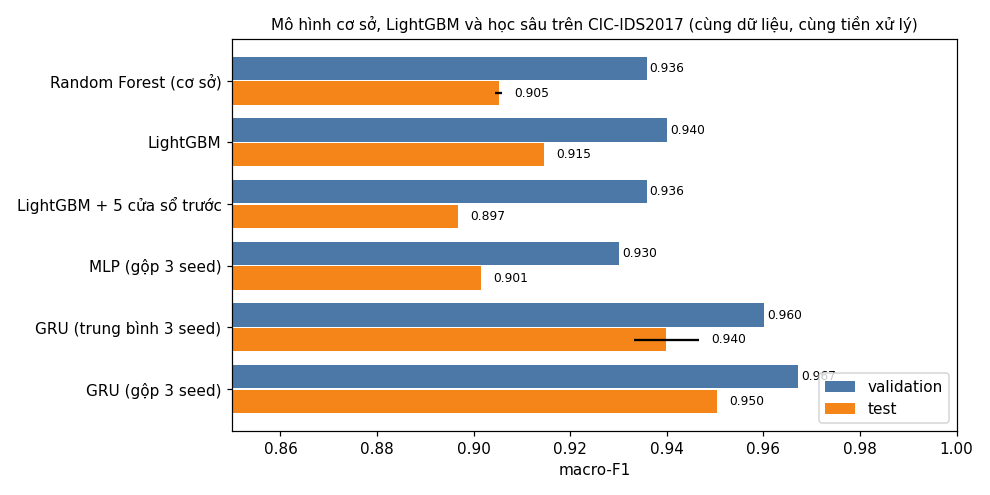

In [6]:
d = json.loads((H / "hoc_sau" / "hoc_sau.json").read_text(encoding="utf-8"))
display(pd.DataFrame({k: {"validation": v["macro_f1_validation"]["trung_binh"], "test": v["macro_f1_test"]["trung_binh"],
                          "test_do_lech": v["macro_f1_test"]["do_lech"]} for k, v in d["mo_hinh"].items()}).T)
display(Image(filename=str(H / "hoc_sau" / "so_sanh_hoc_sau.png")))